=== OUTPUT NOMOR 1: ANALISIS ANOMALI GRAVITASI & SESAR ===


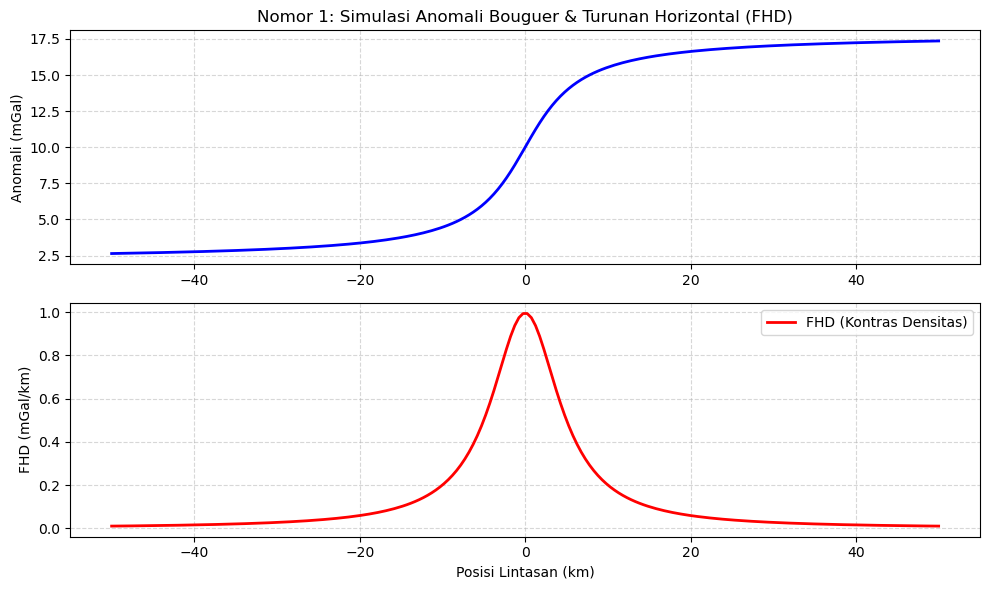


=== OUTPUT NOMOR 2: MODEL RESISTIVITAS PANAS BUMI ===


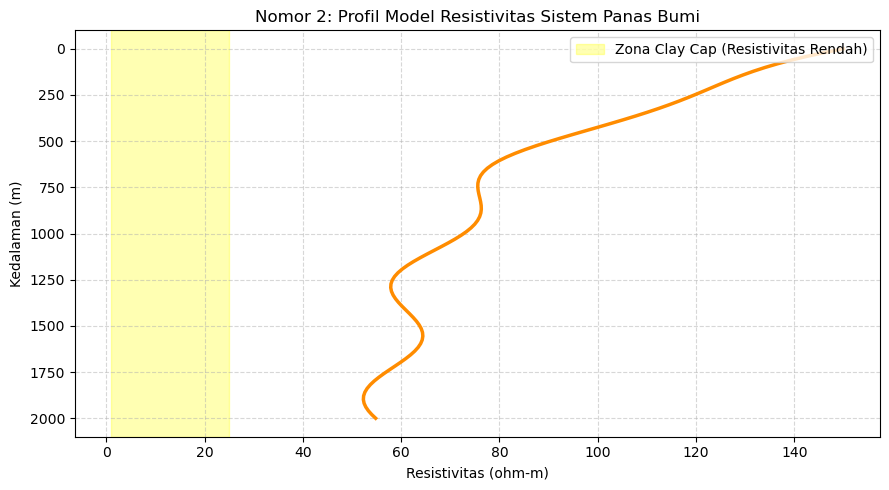


=== OUTPUT NOMOR 3: DISTRIBUSI HIPOSENTER GEMPA VULKANIK ===


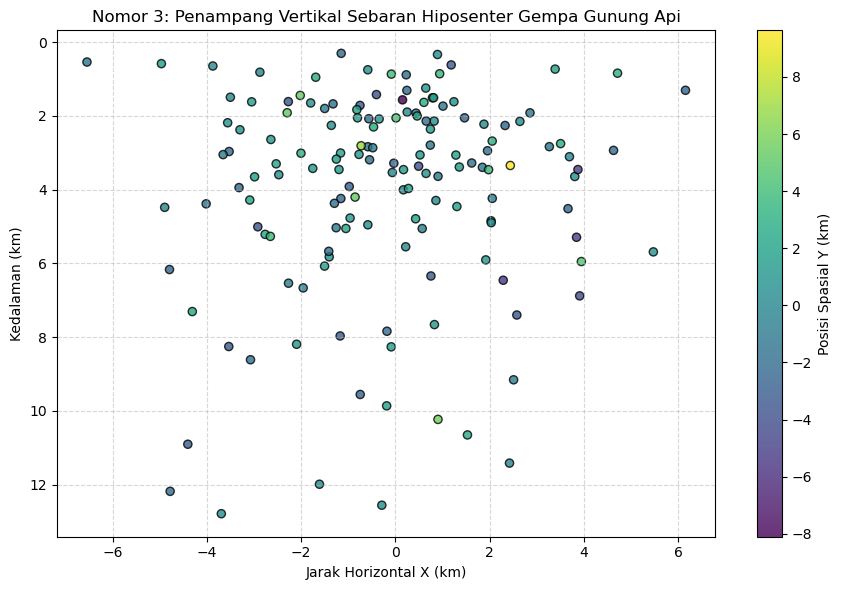


=== OUTPUT NOMOR 4: KURVA RATA-RATA HVSR MIKROTREMOR ===


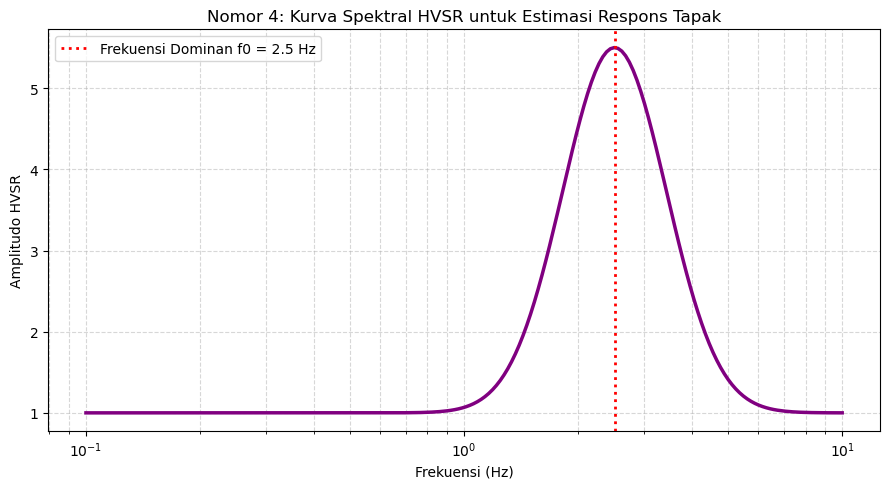


=== OUTPUT NOMOR 5: KURVA WAKTU TEMPUH SEISMIK REFRAKSI ===


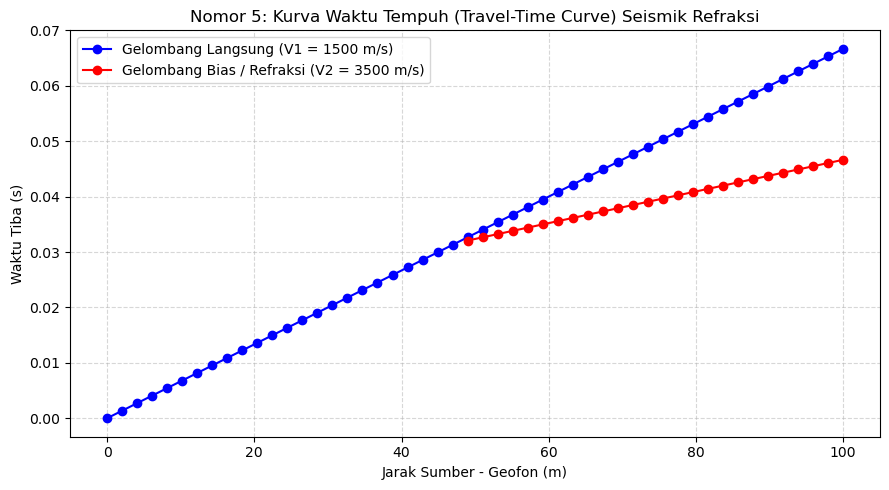

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# NOMOR 1: Identifikasi Zona Sesar (Gravitasi)
# ==========================================
print("=== OUTPUT NOMOR 1: ANALISIS ANOMALI GRAVITASI & SESAR ===")
x_grav = np.linspace(-50, 50, 200)
# Model anomali kontak sesar
bouguer_anomaly = 10.0 + 5.0 * np.arctan(x_grav / 5.0)
fhd = np.gradient(bouguer_anomaly, x_grav) # First Horizontal Derivative

plt.figure(figsize=(10, 6), dpi=100)
plt.subplot(2, 1, 1)
plt.plot(x_grav, bouguer_anomaly, color='blue', linewidth=2)
plt.title("Nomor 1: Simulasi Anomali Bouguer & Turunan Horizontal (FHD)")
plt.ylabel("Anomali (mGal)")
plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(2, 1, 2)
plt.plot(x_grav, fhd, color='red', linewidth=2, label='FHD (Kontras Densitas)')
plt.xlabel("Posisi Lintasan (km)")
plt.ylabel("FHD (mGal/km)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()


# ==========================================
# NOMOR 2: Eksplorasi Panas Bumi (Resistivitas)
# ==========================================
print("\n=== OUTPUT NOMOR 2: MODEL RESISTIVITAS PANAS BUMI ===")
depth = np.linspace(0, 2000, 100)
resistivity = 100 * np.exp(-depth/500) + 10 * np.sin(depth/200)**2 + 50

plt.figure(figsize=(9, 5), dpi=100)
plt.plot(resistivity, depth, color='darkorange', linewidth=2.5)
plt.gca().invert_yaxis()
plt.axvspan(1, 25, color='yellow', alpha=0.3, label='Zona Clay Cap (Resistivitas Rendah)')
plt.title("Nomor 2: Profil Model Resistivitas Sistem Panas Bumi")
plt.xlabel("Resistivitas (ohm-m)")
plt.ylabel("Kedalaman (m)")
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


# ==========================================
# NOMOR 3: Seismologi Gunung Api (Hiposenter)
# ==========================================
print("\n=== OUTPUT NOMOR 3: DISTRIBUSI HIPOSENTER GEMPA VULKANIK ===")
np.random.seed(42)
n_events = 150
hypo_x = np.random.normal(0, 2.5, n_events)
hypo_y = np.random.normal(0, 2.5, n_events)
hypo_z = np.random.gamma(2, 2, n_events)

plt.figure(figsize=(9, 6), dpi=100)
sc = plt.scatter(hypo_x, hypo_z, c=hypo_y, cmap='viridis', s=35, edgecolor='k', alpha=0.8)
plt.gca().invert_yaxis()
plt.colorbar(sc, label='Posisi Spasial Y (km)')
plt.title("Nomor 3: Penampang Vertikal Sebaran Hiposenter Gempa Gunung Api")
plt.xlabel("Jarak Horizontal X (km)")
plt.ylabel("Kedalaman (km)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


# ==========================================
# NOMOR 4: Kerentanan Likuefaksi (Mikrotremor HVSR)
# ==========================================
print("\n=== OUTPUT NOMOR 4: KURVA RATA-RATA HVSR MIKROTREMOR ===")
freq = np.logspace(-1, 1, 200)
f0 = 2.5 # Frekuensi dominan (Hz)
hvsr_amp = 1.0 + 4.5 * np.exp(-((np.log(freq) - np.log(f0))**2) / 0.2)

plt.figure(figsize=(9, 5), dpi=100)
plt.semilogx(freq, hvsr_amp, color='purple', linewidth=2.5)
plt.axvline(f0, color='red', linestyle=':', linewidth=2, label=f'Frekuensi Dominan f0 = {f0} Hz')
plt.title("Nomor 4: Kurva Spektral HVSR untuk Estimasi Respons Tapak")
plt.xlabel("Frekuensi (Hz)")
plt.ylabel("Amplitudo HVSR")
plt.grid(True, which="both", linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()


# ==========================================
# NOMOR 5: Seismik Refraksi (Ketebalan Sedimen)
# ==========================================
print("\n=== OUTPUT NOMOR 5: KURVA WAKTU TEMPUH SEISMIK REFRAKSI ===")
distance = np.linspace(0, 100, 50)
v1 = 1500.0  # Kecepatan lapisan 1 (m/s)
v2 = 3500.0  # Kecepatan lapisan 2 (m/s)
z1 = 15.0    # Ketebalan lapisan 1 (m)

t_direct = distance / v1
x_c = 2 * z1 * np.sqrt((v2 + v1) / (v2 - v1))
t_refracted = np.where(distance >= x_c, (distance / v2) + (2 * z1 * np.sqrt(v2**2 - v1**2) / (v1 * v2)), np.nan)

plt.figure(figsize=(9, 5), dpi=100)
plt.plot(distance, t_direct, 'bo-', label='Gelombang Langsung (V1 = 1500 m/s)')
plt.plot(distance, t_refracted, 'ro-', label='Gelombang Bias / Refraksi (V2 = 3500 m/s)')
plt.title("Nomor 5: Kurva Waktu Tempuh (Travel-Time Curve) Seismik Refraksi")
plt.xlabel("Jarak Sumber - Geofon (m)")
plt.ylabel("Waktu Tiba (s)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()